# Discovering Book Purchase Patterns with Association Rules

## Overview

This notebook examines **700 purchase transactions** recorded for seven book titles. Each record is a basket of binary indicators: `1` means a book appears in that transaction and `0` means it does not.

The analysis uses **Apriori** to identify frequently co-purchased sets of books, then derives association rules to examine how purchase patterns vary with **support, confidence, lift, leverage, and conviction**. Two ranking strategies are explored: thresholds based on the 75th percentile and shortlists containing roughly the top 10% of rules.

Association rules describe patterns in the observed baskets; they do not establish causes or predict the outcome of a promotion.


## 1. Inspecting the transaction records

The dataset contains seven item columns and 700 transactions. Before mining frequent sets, inspect the first records, summary statistics, completeness, and the number of purchases for each title. The bar chart provides a quick overview of which books occur most often.

The source records and book-title labels are retained so every generated itemset and rule remains directly comparable with the original analysis.


Dataset Preview:
   Student Social Life Attractions in Dublin  \
0                                          1   
1                                          1   
2                                          1   
3                                          1   
4                                          1   

   Python Programming for Beginners  Introduction to Data Mining  \
0                                 0                            0   
1                                 0                            0   
2                                 0                            0   
3                                 0                            0   
4                                 0                            0   

   Quick Meals for Busy Students  Introduction to Student Psychology  \
0                              0                                   0   
1                              0                                   0   
2                              0                                   0 

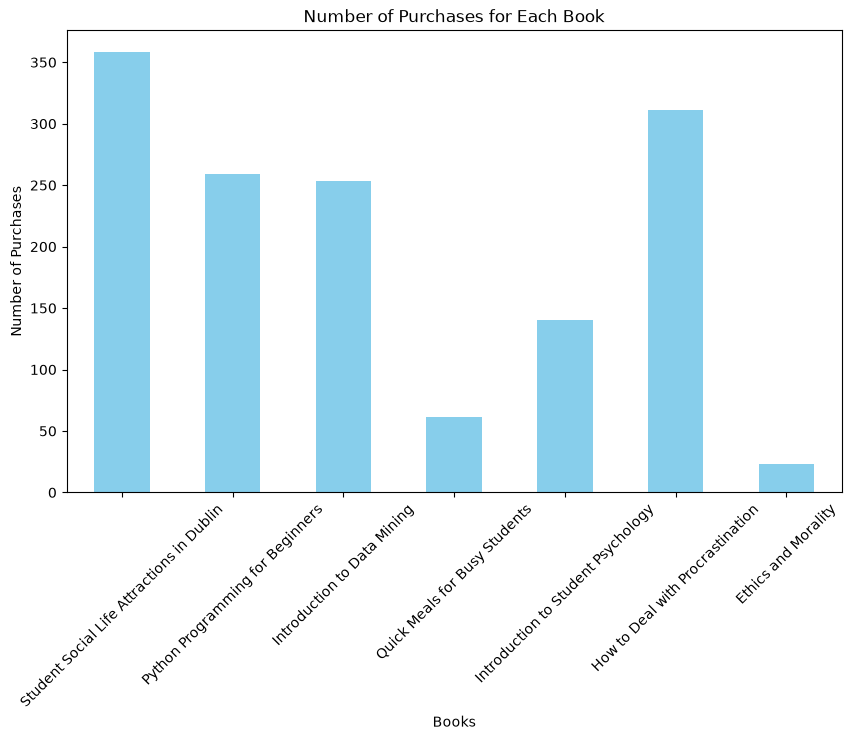

In [1]:
# Load data-inspection and plotting dependencies.
import pandas as pd
import matplotlib.pyplot as plt

# Read the original transaction records using the new filename.
file_path = 'data/book_transactions.csv'  # Dataset contents and column labels are unchanged.
data = pd.read_csv(file_path)

# Inspect the first transactions.
print("Dataset Preview:")
print(data.head())

# Confirm that purchase indicators contain no null entries.
print("\nMissing Values:")
print(data.isnull().sum())

# Review per-item descriptive statistics.
print("\nDataset Summary:")
print(data.describe())

# Inspect column types and non-null counts.
print("\nDataset Structure:")
print(data.info())

# Count how many baskets contain each book.
print("\nItem Purchase Counts:")
print(data.sum())

# Compare item popularity visually.
# Display one bar per book title.
data.sum().plot(kind='bar', figsize=(10, 6), color='skyblue')
plt.title('Number of Purchases for Each Book')
plt.xlabel('Books')
plt.ylabel('Number of Purchases')
plt.xticks(rotation=45)
plt.show()

### Findings from the initial inspection

The saved outputs show **700 complete records** across **seven binary fields**, with no missing values. *Student Social Life Attractions in Dublin* appears in **358 of 700 baskets (51.14%)**, whereas *Ethics and Morality* appears in **23 of 700 (3.29%)**.

These differences describe individual-item popularity only. To investigate combinations, the next stage examines how frequently groups of titles appear together.


## 2. Mining frequent itemsets

The Apriori algorithm finds combinations that satisfy a chosen **minimum support**. Here, `min_support = 0.10` retains an itemset only when it occurs in at least **10% of the 700 transactions**.

The notebook removes duplicate column names, converts the purchase indicators to Boolean values, and calls Apriori with `use_colnames=True`. The saved run reports **21 frequent itemsets** and, using a minimum lift threshold of 1, **64 association rules**.


In [2]:
# Import frequent-itemset and rule-mining utilities.
from mlxtend.frequent_patterns import apriori, association_rules
import pandas as pd

# Prepare the binary transaction matrix.
# Discard duplicate column names, then interpret 0/1 as False/True.
data_clean = data.loc[:, ~data.columns.duplicated()]
data_bools = data_clean.astype(bool)

# Require each reported itemset to appear in at least 10% of baskets.
min_support = 0.1

# Discover itemsets satisfying the support requirement.
# Preserve itemsets of any qualifying length.
frequent_itemsets = apriori(data_bools, min_support=min_support, use_colnames=True)

# Build rules from the frequent itemsets.
# Confidence and lift are derived from the itemset supports.
# The minimum lift here is one.
rules = association_rules(
    frequent_itemsets, 
    metric="lift", 
    min_threshold=1
)

# Record antecedent and consequent sizes for later inspection.
# These columns do not change the discovered rules.
rules["antecedent_len"] = rules["antecedents"].apply(lambda x: len(x))
rules["consequent_len"] = rules["consequents"].apply(lambda x: len(x))

# Summarize the number of itemsets, rules, and leading lift values.
print(f"Number of frequent itemsets found: {len(frequent_itemsets)}")
print(f"Number of rules generated: {len(rules)}")

print("\nTop 5 Association Rules (Sorted by Lift):")
print(rules.sort_values("lift", ascending=False).head())

Number of frequent itemsets found: 21
Number of rules generated: 64

Top 5 Association Rules (Sorted by Lift):
                                          antecedents  \
54  frozenset({Introduction to Data Mining, How to...   
59  frozenset({Student Social Life Attractions in ...   
58  frozenset({How to Deal with Procrastination, P...   
55  frozenset({Introduction to Data Mining, Studen...   
53  frozenset({How to Deal with Procrastination, S...   

                                          consequents  antecedent support  \
54  frozenset({Student Social Life Attractions in ...            0.224286   
59  frozenset({Introduction to Data Mining, How to...            0.204286   
58  frozenset({Introduction to Data Mining, Studen...            0.217143   
55  frozenset({How to Deal with Procrastination, P...            0.212857   
53           frozenset({Introduction to Data Mining})            0.135714   

    consequent support   support  confidence      lift  representativity  \
54     

In [3]:
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# Rebuild a Boolean matrix with unique feature names.
data_clean = data.loc[:, ~data.columns.duplicated()]
data_bools = data_clean.astype(bool)

# Extract the same support-qualified itemsets.
min_support = 0.1
frequent_itemsets = apriori(data_bools, min_support=min_support, use_colnames=True)

# Include the full rule distribution for percentile ranking.
# A zero lift threshold avoids excluding lower-lift rules.
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=0)

# Establish a cutoff at the upper quartile of each metric.
# The qualifying subsets may overlap.
metrics = ['confidence', 'lift', 'leverage']
thresholds = {}

for metric in metrics:
    # Calculate each cutoff from its corresponding metric values.
    thresholds[metric] = np.percentile(rules[metric], 75)

# Retain all rules at or above the metric-specific cutoff.
rules_by_metric = {}
for metric, threshold in thresholds.items():
    rules_by_metric[metric] = rules[rules[metric] >= threshold]

# Report the cutoffs and shortlisted rules.

print("\nFrequent Itemsets:")
print(frequent_itemsets.head()) # Limit the displayed itemsets for compact output.

print("\nPercentile Thresholds (Top 25%):")
for m, t in thresholds.items():
    print(f"{m.capitalize()}: {t:.4f}")

for metric, filtered_rules in rules_by_metric.items():
    print(f"\nRules filtered by {metric} (Count: {len(filtered_rules)}):")
    # Show no more than ten rows in each printed ranking.
    print(filtered_rules.sort_values(metric, ascending=False).head(10))


Frequent Itemsets:
    support                                           itemsets
0  0.511429  frozenset({Student Social Life Attractions in ...
1  0.370000      frozenset({Python Programming for Beginners})
2  0.361429           frozenset({Introduction to Data Mining})
3  0.200000    frozenset({Introduction to Student Psychology})
4  0.444286      frozenset({How to Deal with Procrastination})

Percentile Thresholds (Top 25%):
Confidence: 0.6607
Lift: 1.8352
Leverage: 0.0611

Rules filtered by confidence (Count: 16):
                                          antecedents  \
39  frozenset({Introduction to Student Psychology,...   
53  frozenset({How to Deal with Procrastination, S...   
38  frozenset({Introduction to Student Psychology,...   
18    frozenset({Introduction to Student Psychology})   
52  frozenset({Introduction to Data Mining, Studen...   
51  frozenset({Introduction to Data Mining, How to...   
33  frozenset({Introduction to Data Mining, Studen...   
4     frozenset({Int

In [4]:
# Illustrate one qualifying rule from each metric-based shortlist.
for metric, filtered_rules in rules_by_metric.items():
    print(f"\nRules filtered by {metric} (threshold: {thresholds[metric]:.2f}):")
    # Choose the first rule also meeting minimum support and confidence.
    selected_rule = filtered_rules[(filtered_rules['support'] >= 0.1) & (filtered_rules['confidence'] >= 0.7)].iloc[0]
    # Retrieve the values needed to describe that rule.
    antecedents = selected_rule['antecedents']
    consequents = selected_rule['consequents']
    support = selected_rule['support']
    confidence = selected_rule['confidence']
    lift = selected_rule['lift']
    leverage = selected_rule['leverage']
    conviction = selected_rule['conviction']
    # Show its direction and association statistics.
    print(f"Selected Rule: {antecedents} -> {consequents}")
    print(f"Support: {support:.2f}, Confidence: {confidence:.2f}, Lift: {lift:.2f}, Leverage: {leverage:.2f}, Conviction: {conviction:.2f}")
    # Interpret the selected metrics in the printed summary.
    print("Interpretation:")
    print(f"If {antecedents} is purchased, {consequents} is likely to be bought as well.")
    print(f"Confidence: {confidence:.2f} ({confidence*100}% of transactions).")
    print(f"Lift: {lift:.2f} suggests a stronger association than random chance.")
    print(f"Leverage: {leverage:.2f} shows significant relationship.")
    print(f"Conviction: {conviction:.2f} reflects the likelihood of {consequents} being purchased with {antecedents}.")
    print("\n")



Rules filtered by confidence (threshold: 0.66):
Selected Rule: frozenset({'Introduction to Student Psychology'}) -> frozenset({'Student Social Life Attractions in Dublin'})
Support: 0.14, Confidence: 0.71, Lift: 1.40, Leverage: 0.04, Conviction: 1.71
Interpretation:
If frozenset({'Introduction to Student Psychology'}) is purchased, frozenset({'Student Social Life Attractions in Dublin'}) is likely to be bought as well.
Confidence: 0.71 (71.42857142857142% of transactions).
Lift: 1.40 suggests a stronger association than random chance.
Leverage: 0.04 shows significant relationship.
Conviction: 1.71 reflects the likelihood of frozenset({'Student Social Life Attractions in Dublin'}) being purchased with frozenset({'Introduction to Student Psychology'}).



Rules filtered by lift (threshold: 1.84):
Selected Rule: frozenset({'Student Social Life Attractions in Dublin', 'Python Programming for Beginners'}) -> frozenset({'Introduction to Data Mining'})
Support: 0.14, Confidence: 0.71, Lift: 

### Selecting rules by their metric distributions

A second rule-generation pass uses a lift threshold of zero so that the percentile comparisons are formed from the full rule distribution. The saved **75th-percentile cutoffs** are:

| Metric | 75th-percentile threshold | Rules meeting threshold |
|---|---:|---:|
| Confidence | 0.6607 | 16 |
| Lift | 1.8352 | 16 |
| Leverage | 0.0611 | 18 |

The groups overlap: a rule can qualify under multiple criteria. The subsequent demonstration selects the **first** rule in each filtered group that also meets support ≥ 0.10 and confidence ≥ 0.70. This is an illustrative selection, not a claim that each rule is the strongest by its metric.


## 3. Generating and interpreting association rules

Association rules are written as **antecedent → consequent**: the left side is a set of books observed in a basket, and the right side is another set of books observed alongside it.

- **Support** is the proportion of all transactions containing both sides of the rule.
- **Confidence** is the proportion of baskets containing the antecedent that also contain the consequent.
- **Lift** compares the observed confidence with the consequent's overall prevalence; lift greater than 1 indicates positive association in this sample.
- **Leverage** measures the difference between observed joint support and joint support expected under independence.
- **Conviction** provides a directional measure based on how often the consequent is absent when the antecedent occurs.

This section regenerates the **64 rules** from the same support-filtered itemsets and displays their metrics for comparison.


In [5]:

# Interpret each purchase indicator as a Boolean feature.
data = data.astype(bool)

# Keep the original 10% support floor.
min_support = 0.1

# Mine the qualifying book combinations.
frequent_itemsets = apriori(data, min_support=min_support, use_colnames=True)

# Compute rule statistics for combinations meeting the lift cutoff.
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1, num_itemsets=3)

# Inspect the resulting rules and their associated measures.
print("Association Rules:")
print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage', 'conviction']])


Association Rules:
                                          antecedents  \
0   frozenset({Student Social Life Attractions in ...   
1       frozenset({Python Programming for Beginners})   
2            frozenset({Introduction to Data Mining})   
3   frozenset({Student Social Life Attractions in ...   
4     frozenset({Introduction to Student Psychology})   
..                                                ...   
59  frozenset({Student Social Life Attractions in ...   
60           frozenset({Introduction to Data Mining})   
61      frozenset({How to Deal with Procrastination})   
62  frozenset({Student Social Life Attractions in ...   
63      frozenset({Python Programming for Beginners})   

                                          consequents   support  confidence  \
0       frozenset({Python Programming for Beginners})  0.204286    0.399441   
1   frozenset({Student Social Life Attractions in ...  0.204286    0.552124   
2   frozenset({Student Social Life Attractions in ...  0.21

### Reading the rule table

The saved table contains **64 rules** meeting the `lift >= 1` criterion. For example, the rule *Introduction to Data Mining → Python Programming for Beginners* has **support 0.2186**, **confidence 0.6047**, and **lift 1.6344**. This means the pair occurs in roughly 21.9% of baskets, and approximately 60.5% of baskets containing the data-mining book also contain the Python book.

The notebook also contains more complex rules with two books on one or both sides. Their lift values should not be interpreted as causal effects, and a large lift need not coincide with the highest number of co-purchases.


## 4. Ranking rules by complementary criteria

A subsequent ranking procedure sorts the rules by three different scores and retains `int(len(rules) * 0.1)` entries per ranking. With 64 rules, each **top-decile shortlist contains six rules**:

1. **Confidence ranking:** rules whose consequents most often accompany their antecedents; the displayed columns also include support.
2. **Lift ranking:** rules showing the largest relative departure from independence.
3. **Leverage ranking:** rules showing the largest absolute increase in joint frequency compared with independence.

This **top-10% ranking** is separate from the **75th-percentile filtering** performed earlier. Although the first shortlist is labelled a support-confidence framework in the code, the actual sort key is confidence alone.


In [6]:
# Apply the same minimum support used in earlier sections.
min_support = 0.1

# Build the itemset collection used for ranking.
frequent_itemsets = apriori(data, min_support=min_support, use_colnames=True)

# Generate rules before comparing individual metrics.
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1, num_itemsets=3)

# Retain roughly the highest tenth by confidence.
support_confidence_rules = rules.sort_values(by='confidence', ascending=False).head(int(len(rules) * 0.1))

# Retain roughly the highest tenth by relative association (lift).
lift_rules = rules.sort_values(by='lift', ascending=False).head(int(len(rules) * 0.1))

# Retain roughly the highest tenth by absolute excess co-occurrence.
leverage_rules = rules.sort_values(by='leverage', ascending=False).head(int(len(rules) * 0.1))

# Print the metric-specific shortlists.
print("Support-Confidence Framework Rules:")
print(support_confidence_rules[['antecedents', 'consequents', 'support', 'confidence']])

print("\nLift-Based Rules:")
print(lift_rules[['antecedents', 'consequents', 'support', 'lift']])

print("\nLeverage-Based Rules:")
print(leverage_rules[['antecedents', 'consequents', 'support', 'leverage']])

Support-Confidence Framework Rules:
                                          antecedents  \
39  frozenset({Introduction to Student Psychology,...   
53  frozenset({How to Deal with Procrastination, S...   
38  frozenset({Introduction to Student Psychology,...   
18    frozenset({Introduction to Student Psychology})   
52  frozenset({Introduction to Data Mining, Studen...   
51  frozenset({Introduction to Data Mining, How to...   

                                          consequents   support  confidence  
39      frozenset({How to Deal with Procrastination})  0.114286    0.800000  
53           frozenset({Introduction to Data Mining})  0.107143    0.789474  
38  frozenset({Student Social Life Attractions in ...  0.114286    0.761905  
18      frozenset({How to Deal with Procrastination})  0.150000    0.750000  
52      frozenset({How to Deal with Procrastination})  0.107143    0.742574  
51  frozenset({Student Social Life Attractions in ...  0.107143    0.721154  

Lift-Based Rules:

### What the three rankings reveal

The recorded top-decile tables prioritize different relationships. The **highest confidence** is **0.8000** for a multi-book antecedent leading to *How to Deal with Procrastination*. The strongest reported **lift** is **2.3384**, shared by reverse-direction rules between two-item sets. The largest **leverage** is **0.08484**, achieved by the pair *Introduction to Data Mining* and *Python Programming for Beginners* (in either direction).

Because each ranking rewards a different statistical property, none should be interpreted as a universal definition of the best recommendation. The next section prints a representative top-ranked rule for each criterion.


## 5. Examining representative rules

The following cell takes the first rule from each top-decile shortlist and prints its antecedent, consequent, support, confidence, lift, leverage, and conviction. These saved values make the comparisons traceable, even when pandas shortens long book-title combinations in its display.


In [7]:
# Examine the first rule in each previously sorted shortlist.
# Take the leading confidence-ranked entry.
support_confidence_rule = support_confidence_rules.iloc[0]

# Take the leading lift-ranked entry.
lift_rule = lift_rules.iloc[0]

# Take the leading leverage-ranked entry.
leverage_rule = leverage_rules.iloc[0]

# Report each selection with the same diagnostic measures.
print("Support-Confidence Rule:")
print(support_confidence_rule[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage', 'conviction']])

print("\nLift-Based Rule:")
print(lift_rule[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage', 'conviction']])

print("\nLeverage-Based Rule:")
print(leverage_rule[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage', 'conviction']])


Support-Confidence Rule:
antecedents    frozenset({Introduction to Student Psychology,...
consequents        frozenset({How to Deal with Procrastination})
support                                                 0.114286
confidence                                                   0.8
lift                                                    1.800643
leverage                                                0.050816
conviction                                              2.778571
Name: 39, dtype: object

Lift-Based Rule:
antecedents    frozenset({Introduction to Data Mining, How to...
consequents    frozenset({Student Social Life Attractions in ...
support                                                 0.107143
confidence                                              0.477707
lift                                                    2.338426
leverage                                                0.061324
conviction                                              1.523502
Name: 54, dtype: object

### Representative results from the saved output

| Selection | Consequent / relationship | Support | Confidence | Lift | Leverage |
|---|---|---:|---:|---:|---:|
| Highest confidence | A two-book antecedent → *How to Deal with Procrastination* | 0.1143 | 0.8000 | 1.8006 | 0.0508 |
| Highest lift | A two-book set → another two-book set | 0.1071 | 0.4777 | 2.3384 | 0.0613 |
| Highest leverage | *Introduction to Data Mining* → *Python Programming for Beginners* | 0.2186 | 0.6047 | 1.6344 | 0.0848 |

The high-lift rule is less frequent than the high-leverage book pair. This illustrates why absolute prevalence and relative association strength should be considered together. Long antecedents are described by size here because the stored printed tables truncate some item names; the full rule objects remain in the notebook.


## 6. Discussion and limitations

### Interpretation

The analysis provides multiple ways of shortlisting book combinations. The **data-mining and Python** pair has the largest reported leverage, making it a natural candidate for exploring a related-book suggestion. The highest-lift rules capture less common but comparatively strong co-purchase patterns. The confidence ranking favors rules whose consequents are common among baskets containing the antecedent.

### Cautions

- The dataset contains **700 transactions**. Rule strengths may differ in another sample or time period.
- A support floor of **0.10** excludes less frequent combinations, including rules involving rare books.
- The 75th-percentile and top-decile filters are **in-sample rankings**, not independent validation.
- A book being purchased with another is **not evidence** that one purchase caused the other.
- No purchase dates, customer context, or controlled promotion results are available in these records.

An operational recommendation would need prospective evaluation, ideally with a holdout period or controlled experiment.


## Conclusion

Using Apriori at **10% minimum support**, the saved notebook identifies **21 frequent itemsets** and **64 rules** under the specified lift filter. The ranking experiments demonstrate how confidence, lift, and leverage can highlight different subsets of those rules.

The clearest high-leverage example is **Introduction to Data Mining → Python Programming for Beginners** (leverage **0.08484**, lift **1.6344**). This could motivate testing a related-item recommendation, but the dataset alone cannot establish an increase in purchases or any causal effect.

**Practical next step:** select a small number of candidates using both association strength and frequency, then evaluate them against new transactions before using them in an automated recommendation system.

**Reproducibility:** the analysis uses `data/book_transactions.csv`, whose values and book-title columns are unchanged from the supplied data. Existing outputs in this notebook are preserved for reference; this revision does not execute cells.
